# Assignment-12: Custom MLP for Imbalanced Tabular Classification
## Problem Statement: Predicting Credit Card Defaults

In this assignment, you will step away from clean, balanced computer vision datasets (like MNIST) and tackle a real-world financial dataset: the **UCI Default of Credit Card Clients Dataset**. The dataset is uploaded in the same git folder for your reference.

Because this dataset exhibits significant class imbalance (~22% defaults vs ~78% non-defaults), standard training and evaluation routines will fail. You must implement advanced data management, specialized loss scaling, and detailed metric tracking using PyTorch's core architecture.

### Objectives:
1. Handle categorical, numerical, and imbalanced data in a custom PyTorch pipeline.
2. Build a modular MLP architecture using `nn.Module`, initializing weights appropriately.
3. Incorporate a weighted loss function to combat class imbalance.
4. Implement diagnostic checks to monitor gradient health (vanishing gradients) during training.
5. Evaluate your model using metrics robust to severe class imbalance.

### Steps to solve and upload the assignment 

- Download the notebook in your local machine.
- Solve the questions in the notebook and save it.
- Rename the file as `Assignment-12-<your_name>_<your_surname>.ipynb`. For example if your name is Dipika Chopra then name the file as `Assignment-12-Dipika_Chopra.ipynb`.
- Upload the solved notebook to your respective github repository.
- Upload the solved notebook and the scanned pdf copy of the solutions in the google drive location: https://drive.google.com/drive/folders/1WyYyfoJxpvHUZANqXyksOW3FSSsEN-Z9?usp=sharing

## Step 1: Preprocessing & Custom Stratified Datasets

Load your dataset using Pandas. Note that the target column is `default.payment.next.month`. 

**Your Tasks:**
1. **Feature Separation:** Clean the dataset by removing the `ID` column. Identify which features are continuous (e.g., `LIMIT_BAL`, `BILL_AMT1`) and which are categorical/ordinal (e.g., `SEX`, `EDUCATION`, `MARRIAGE`, `PAY_0`).
2. **Feature Scaling:** Normalize continuous variables using `StandardScaler`. 
3. **Stratified Train/Val/Test Split:** Split the data into 80% Train, 10% Validation, and 10% Test. Crucially, ensure the split is **stratified** based on the target class.
4. **PyTorch Pipeline:** Build a custom `Dataset` class overriding `__init__`, `__len__`, and `__getitem__`. Construct training, validation, and test `DataLoader` instances with an appropriate batch size.

---
### Intelligent Design Questions
* **Question 1.1:** Why is a standard random train/test split dangerous for highly imbalanced datasets? What specific problem could manifest in our 10% validation or test sets if stratification is omitted?

The Simple Explanation:
Imagine your dataset has very few default cases (only about 10% to 22% of the whole dataset). If you use a completely random split without looking at the classes, pure luck might cause your 10% validation or test set to end up with zero or almost zero default cases.

The Problem That Manifests:
If your test set has no defaults, your model has nothing to be tested against for default detection. More importantly, your model might train on a partition that completely misses the rare class, or your evaluation scores will become completely broken and unreliable. Stratification solves this by forcing the training and test sets to keep the exact same percentage of defaults (e.g., ~22%) as the original dataset.

* **Question 1.2:** Why must we fit the `StandardScaler` *only* on the training partition instead of scaling the entire raw dataset before the split?

The Simple Explanation:
Fitting a scaler means calculating the average (mean) and spread (standard deviation) of your data. If you scale the entire dataset before splitting, information from your test/validation set (like its mean and standard deviation) leaks into your training data.

Why This is Dangerous (Data Leakage):
In the real world, your model will be used on future, completely unseen customers. If your training data already "knows" information about the test set, your model will look artificially accurate during testing, but fail badly in production because it cheated by seeing future information early. You must compute the scaler statistics strictly on the training set and just apply those same numbers to transform the test set.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch.utils.data import Dataset, DataLoader

### 1. Load the Dataset into data variable

In [2]:
data = pd.read_csv("./UCI_Credit_Card.csv")
data.head(5)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


### 2. Remove the ID column

In [3]:
if "ID" in data.columns:
    data = data.drop(columns=['ID'])

In [6]:
data.head(5)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [ ]:
# Step-by-Step Feature Engineering Code

# 1. Handle Skewed Monetary Features with Log Transformation (np.log1p handles large numbers smoothly)
skewed_cols = ['LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 
               'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

for col in skewed_cols:
    data[col] = np.log1p(data[col].clip(lower=0))


# 2. Create Powerful Financial Ratios & Behavioral Indicators
# Credit Utilization: How much of their max credit limit are they currently using on their latest bill?
data['CREDIT_UTIL_1'] = data['BILL_AMT1'] / (data['LIMIT_BAL'] + 1e-5)

# Payment-to-Bill Ratio: Did they pay off what they owed last month?
data['PAY_TO_BILL_1'] = data['PAY_AMT1'] / (data['BILL_AMT2'] + 1e-5)

# Max Payment Delay: What was the worst payment delay across the past 6 months?
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
data['MAX_PAY_DELAY'] = data[pay_cols].max(axis=1)

# Average Payment Delay: Is the client consistently late or just had one bad month?
data['AVG_PAY_DELAY'] = data[pay_cols].mean(axis=1)

print("Feature engineering complete! New columns added.")
print(f"Total features now: {data.shape[1] - 1}") # Excluding the target column

Feature engineering complete! New columns added.
Total features now: 27


In [65]:
import numpy as np
import pandas as pd

# Assuming your dataframe is named 'data'
# 1. Payment Delay Velocity / Trend
# Are payment delays worsening recently? (Compare most recent PAY_0 to older PAY_6)
data['PAY_DELAY_TREND'] = data['PAY_0'] - data['PAY_6']

# 2. Maximum Payment Delay across all recorded months (if not already created)
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
data['MAX_PAY_DELAY'] = data[pay_cols].max(axis=1)

# 3. Average Payment Delay
data['AVG_PAY_DELAY'] = data[pay_cols].mean(axis=1)

# 4. Credit Utilization Trend (Bill Amount relative to Limit Balance)
# Are they maxing out their cards more aggressively recently?
data['CREDIT_UTIL_1'] = data['BILL_AMT1'] / (data['LIMIT_BAL'] + 1)
data['CREDIT_UTIL_6'] = data['BILL_AMT6'] / (data['LIMIT_BAL'] + 1)
data['UTIL_TREND'] = data['CREDIT_UTIL_1'] - data['CREDIT_UTIL_6']

# 5. Payment-to-Bill Ratio Trend (Are they paying less of their bill over time?)
data['PAY_BILL_RATIO_1'] = data['PAY_AMT1'] / (data['BILL_AMT1'] + 1)
data['PAY_BILL_RATIO_6'] = data['PAY_AMT6'] / (data['BILL_AMT6'] + 1)
data['PAY_RATIO_TREND'] = data['PAY_BILL_RATIO_1'] - data['PAY_BILL_RATIO_6']

print(
    'Successfully engineered multi-month trend features! New shape:',
    data.shape,
)

Successfully engineered multi-month trend features! New shape: (30000, 34)


### 3. Seperate Feature(X) and Target(Y)

In [66]:
target_cols = "default.payment.next.month"
X = data.drop(columns=[target_cols])
Y = data[target_cols]

In [67]:
X.shape

(30000, 33)

### 4. Identifying Feature Types

In [68]:
# Categorical/Ordinal features (Demographics + Payment History Statuses)
categorical_features = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

# Continuous Features
continuous_features = [col for col in X.columns if col not in categorical_features]

print(f"Dataset size : rows : {data.shape[0]} - Columns : {data.shape[1]}")
print(f"Continous Feature Count : {len(continuous_features)}")
print(f"Categorical Features Count : {len(categorical_features)}")

Dataset size : rows : 30000 - Columns : 34
Continous Feature Count : 24
Categorical Features Count : 9


### 5 Stratified Train/Validation/Test Split

In [69]:
# First split: Extract 80% for Training and 20% for a temporary Val/Test block
X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.20, random_state=42, stratify=Y)

# Second split: Divide the temporary 20% block equally into 10% Validation and 10% Test
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.50, random_state=42, stratify=Y_temp)



In [70]:
print(f"Train Shape : {X_train.shape} | Validation Shape : {X_val.shape} | Test Shape : {X_test.shape}")
print(f"Train Default Ratio : {Y_train.mean():.4f}")
print(f"Validation Default Ratio : {Y_val.mean():.4f}")

Train Shape : (24000, 33) | Validation Shape : (3000, 33) | Test Shape : (3000, 33)
Train Default Ratio : 0.2212
Validation Default Ratio : 0.2213


- 0 : Non-Default - Who has paid before the due :  77.88%
- 1 : Default - Who has not paid before the due : 22.12%

In [71]:
(Y.value_counts() / Y.shape[0]) * 100

default.payment.next.month
0    77.88
1    22.12
Name: count, dtype: float64

### 6. Feature Scaling

In [72]:
#Initialize the Scaling
scaler = StandardScaler()

# Fit and tranform only the continuous columns
X_train_scaled = X_train.copy()
X_train_scaled[continuous_features] = scaler.fit_transform(X_train[continuous_features])

# 3. Transform (DO NOT FIT) the validation and test continuous sets
X_val_scaled = X_val.copy()
X_val_scaled[continuous_features] = scaler.transform(X_val[continuous_features])

X_test_scaled = X_test.copy()
X_test_scaled[continuous_features] = scaler.transform(X_test[continuous_features])

print("Continuous variables successfully normalized across all partitions.")

Continuous variables successfully normalized across all partitions.


### 7. Credit Default Dataset Custome DataSet and DataLoaders
- Calling .unsqueeze(1) inserts a brand-new, empty dimension at Index 1. [, [0], [1], [0], ... ]

In [73]:
class CreditDefaultDataSet(Dataset):
    def __init__(self, feature_df, labels_series):
        self.X = torch.tensor(feature_df.values, dtype=torch.float32)
        self.Y = torch.tensor(labels_series.values, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.Y)

    def __getitem__(self, index):
        return self.X[index], self.Y[index]

from imblearn.over_sampling import SMOTE

# Apply SMOTE ONLY on the scaled Training data
smote = SMOTE(random_state=42)
X_train_resampled_array, Y_train_resampled_array = smote.fit_resample(X_train_scaled, Y_train)

# Convert the resampled numpy array back into a Pandas DataFrame/Series 
# (this preserves your column names and types for the Custom Dataset wrapper)
X_train_resampled = pd.DataFrame(X_train_resampled_array, columns=X_train.columns)
Y_train_resampled = pd.Series(Y_train_resampled_array)

print(f"Before SMOTE - Training samples: {len(Y_train)}")
print(f"After SMOTE - Training samples: {len(Y_train_resampled)} (Balanced classes!)")

# 2. Instantiate Custom dataset wrappers (Notice we now use the resampled training data!)
train_dataset = CreditDefaultDataSet(X_train_resampled, Y_train_resampled)
val_dataset = CreditDefaultDataSet(X_val_scaled, Y_val)
test_dataset = CreditDefaultDataSet(X_test_scaled, Y_test)

# 3. Generate stream dataloaders
BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, BATCH_SIZE, shuffle=False)

Before SMOTE - Training samples: 24000
After SMOTE - Training samples: 37382 (Balanced classes!)


In [26]:
X_train_scaled

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,CREDIT_UTIL_1,PAY_TO_BILL_1,MAX_PAY_DELAY,AVG_PAY_DELAY
22788,0.340007,2,2,2,-0.264558,2,2,3,2,0,...,0.918339,-2.001046,-1.873268,0.776365,0.982673,0.791001,0.773551,-0.062433,1.911123,1.721333
29006,0.271348,2,1,2,-0.155804,1,-1,-1,-2,-2,...,-0.816245,-2.001046,-1.873268,-1.785923,-1.748147,-1.673047,-2.745169,-0.062428,0.417669,-1.005498
16950,-2.609497,1,2,1,1.584260,1,2,0,0,0,...,-1.707251,0.179965,0.224168,-0.114133,-0.088451,0.280039,0.776792,-0.062449,1.164396,0.698772
22280,0.678790,2,1,2,-0.699574,0,0,0,0,0,...,0.764288,0.773942,0.802231,0.705921,0.715826,0.786329,0.752748,-0.062434,-0.329058,0.187491
11346,1.043629,2,1,2,-0.373312,1,-2,-1,0,0,...,-2.045917,-0.236421,-1.873268,-1.785923,-1.748147,0.331534,-2.745169,-0.062452,0.417669,-0.494217
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23479,-0.160000,2,2,2,-0.482066,0,0,0,0,0,...,0.452496,0.557326,0.694007,0.604575,0.621657,0.664138,0.742676,-0.062435,-0.329058,0.187491
13921,0.033960,2,2,2,-1.243344,0,0,0,0,0,...,0.525979,0.534358,0.607195,0.921653,0.694977,-1.673047,0.750483,-0.062435,1.164396,0.528345
3794,0.033960,2,1,2,-1.243344,0,0,0,0,0,...,0.486915,0.319141,0.395608,0.448647,0.308039,0.280039,0.632217,-0.062434,-0.329058,0.187491
27565,1.202707,1,1,1,2.345538,1,-2,-1,-1,-1,...,-2.045917,0.058640,-0.230540,-1.785923,-1.748147,-1.673047,-2.745169,-0.062452,0.417669,-0.835071


In [22]:
X_train_scaled.info()

<class 'pandas.DataFrame'>
Index: 24000 entries, 22788 to 27126
Data columns (total 27 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   LIMIT_BAL      24000 non-null  float64
 1   SEX            24000 non-null  int64  
 2   EDUCATION      24000 non-null  int64  
 3   MARRIAGE       24000 non-null  int64  
 4   AGE            24000 non-null  float64
 5   PAY_0          24000 non-null  int64  
 6   PAY_2          24000 non-null  int64  
 7   PAY_3          24000 non-null  int64  
 8   PAY_4          24000 non-null  int64  
 9   PAY_5          24000 non-null  int64  
 10  PAY_6          24000 non-null  int64  
 11  BILL_AMT1      24000 non-null  float64
 12  BILL_AMT2      24000 non-null  float64
 13  BILL_AMT3      24000 non-null  float64
 14  BILL_AMT4      24000 non-null  float64
 15  BILL_AMT5      24000 non-null  float64
 16  BILL_AMT6      24000 non-null  float64
 17  PAY_AMT1       24000 non-null  float64
 18  PAY_AMT2       240

## Step 2: Custom MLP Architecture with Modular Control

Create an explicit network subclassing `nn.Module`. Avoid wrapping your entire model within a single massive `nn.Sequential` block; instead, define layers as standalone structural parameters inside `__init__` and pass inputs explicitly through them within the `forward` function.

**Your Architecture Requirements:**
* At least 3 hidden layers.
* Apply **Kaiming (He) Uniform Initialization** explicitly to the weights of your linear layers, and set the biases to zero.
* Use `nn.ReLU` activations for hidden features.
* Include structural regularization using `nn.Dropout` and stabilization via `nn.BatchNorm1d`.

---
### Intelligent Design Questions
* **Question 2.1:** What is the specific mathematical danger of initializing all weights to zero in a deep neural network? How does He Initialization solve this?

The Danger: If all weights are initialized to zero, every neuron in a given layer receives the exact same input values and computes the exact same output. Consequently, during backpropagation, all neurons receive identical gradients and update by the exact same amount. This symmetry problem prevents the network from learning diverse features, rendering deep architectures no more powerful than a single-layer linear model.

How He Initialization Solves It: Kaiming (He) initialization draws weights from a truncated normal or uniform distribution scaled by the fan-in (number of incoming connections). Specifically tailored for layers followed by ReLU activations, it maintains the variance of activations across deep layers, preventing gradients from vanishing or exploding at the start of training.


* **Question 2.2:** What is the standard recommended operational order for a single hidden block containing a Linear Layer, Batch Normalization, Dropout, and a ReLU Activation? Justify the placement of Batch Normalization relative to the activation function.

- Standard Operational Order:$$\text{Linear} \rightarrow \text{BatchNorm1d} \rightarrow \text{ReLU} \rightarrow \text{Dropout}$$Justification for BatchNorm Placement: Batch Normalization is typically placed before the activation function. It centers and scales the pre-activation outputs, ensuring that the inputs fed into the ReLU function do not drift into saturated or negative regions (which can cause "dead ReLUs"). Placing BatchNorm before ReLU allows the non-linear activation to operate on a well-normalized distribution.

### 7. Implementing the MLP 

In [74]:
import torch
import torch.nn as nn

class CustomMLP(nn.Module):
    def __init__(self, input_dim, drop_out_p=0.3):
        super(CustomMLP, self).__init__()

        # Layer 1: 22 -> 128
        self.fc1  = nn.Linear(input_dim, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(drop_out_p)

        # Layer 2: 128 -> 64
        self.fc2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)   # Fixed: Back to 64
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(drop_out_p)

        # Layer 3: 64 -> 32
        self.fc3 = nn.Linear(64, 32)
        self.bn3 = nn.BatchNorm1d(32)   # Fixed: Changed from bn2 to bn3!
        self.relu3 = nn.ReLU()
        self.dropout3 = nn.Dropout(drop_out_p)

        # Output Layer: 32 -> 1
        self.output_layer = nn.Linear(32, 1)

        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_uniform_(m.weight, nonlinearity='relu') # Fixed: added trailing underscore
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)

    def forward(self, x):
        x = self.dropout1(self.relu1(self.bn1(self.fc1(x))))
        x = self.dropout2(self.relu2(self.bn2(self.fc2(x))))
        x = self.dropout3(self.relu3(self.bn3(self.fc3(x)))) # Now uses bn3 correctly

        x = self.output_layer(x)
        return x

# Instantiate and verify
input_features_dim = X_train_scaled.shape[1]
model = CustomMLP(input_dim=input_features_dim)
print(model)

CustomMLP(
  (fc1): Linear(in_features=33, out_features=128, bias=True)
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (bn3): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu3): ReLU()
  (dropout3): Dropout(p=0.3, inplace=False)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)


## Step 3: Weighted Loss, Optimization & Gradient Health Diagnostics

Standard Binary Cross-Entropy treats errors on positive (default) and negative (non-default) examples equally. You will replace it with a weighted variation and construct a training loop that tracks gradient health.

**Your Tasks:**
1. **Loss Selection:** Instantiate `nn.BCEWithLogitsLoss`. Compute and provide the precise `pos_weight` factor required to penalize mistakes on the minority default class more severely.
2. **Optimizer:** Use the `Adam` optimizer with a well-chosen learning rate.
3. **Training Loop:** Write an explicit loop tracking training and validation loss across epochs. 
4. **Early Stopping:** Program a safety condition to halt training if validation loss does not drop for 5 consecutive epochs.
5. **Gradient Inspection Hook:** Inside your training loop (immediately after executing `loss.backward()`), print or log the average absolute gradient magnitude (`.grad.abs().mean()`) of the *first* hidden layer versus the *final* hidden layer every few epochs.

---
### Intelligent Design Questions
* **Question 3.1:** Write down the mathematical formula you used to calculate the `pos_weight` value for this specific dataset.
- `Ans` : Formula:$$\text{pos\_weight} = \frac{\text{Number of Negative Samples (Class 0)}}{\text{Number of Positive Samples (Class 1)}}$$Why it's used: In credit default datasets, non-defaults vastly outnumber defaults (severe class imbalance). Setting pos_weight to this ratio tells the loss function to penalize false negatives (failing to catch a client who defaults) more heavily, balancing the model's attention.

* **Question 3.2:** `nn.BCEWithLogitsLoss` combines a Sigmoid activation and Binary Cross Entropy into one class. Why does PyTorch highly recommend using this unified layer instead of combining a separate `nn.Sigmoid` output layer with a standalone `nn.BCELoss`? 
- `Ans` : Numerical Stability: Applying a separate nn.Sigmoid maps raw scores into probabilities close to $0.0$ or $1.0$. When you subsequently pass those probabilities into a log-based loss function (nn.BCELoss), it can lead to floating-point underflow or overflow (resulting in NaN errors). nn.BCEWithLogitsLoss combines them internally using the Log-Sum-Exp trick, ensuring mathematically stable calculations.

* **Question 3.3:** Based on your gradient logging task, how can you empirically prove whether or not your deep network is suffering from a **Vanishing Gradient** problem in its early layers as training progresses?
- `Ans` : Proof: By tracking .grad.abs().mean() for both the first layer (fc1) and the final layer (output_layer), you can compare their magnitudes. If your model suffers from vanishing gradients, the gradient magnitudes in fc1 will shrink to near-zero (e.g., $10^{-7}$ or smaller) while the final layer maintains healthy magnitudes (e.g., $10^{-2}$), indicating that gradients are dying out before reaching the input layers during backpropagation.

pos_weight = 3.52: This means non-defaults outnumber defaults by about 3.5 to 1. PyTorch automatically uses this 3.52 multiplier to tell the model: "Missing a default is 3.5 times worse than a false alarm, so pay extra attention to the defaults!"

In [75]:
import torch
import torch.nn as nn
import torch.optim as optim

num_negative = (Y_train == 0).sum()
num_positive = (Y_train == 1).sum()

print(f"Negative Sample (0): {num_negative}")
print(f"Postive Sample (1): {num_positive}")
print("SMOTE is active: Using standard BCEWithLogitsLoss without pos_weight.")

# 1. Loss function, AdamW Optimizer, and LR Scheduler
criteria = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-3)

# Reduce LR by half if validation loss doesn't improve for 2 epochs
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# 3. Training Loop with early stopping & gradient diagnostics
epochs = 30
patience = 6  # Slightly increased patience since scheduler helps recover stalls
best_val_loss = float("inf")
patience_counter = 0

print("\nStarting the Training Loop with AdamW & LR Scheduler...")

for epoch in range(epochs):
    model.train()
    train_loss = 0.0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad() 
        outputs = model(batch_x)
        loss = criteria(outputs, batch_y)
        loss.backward() 

        optimizer.step()
        train_loss += loss.item() * batch_x.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation phase
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            outputs = model(batch_x)
            loss = criteria(outputs, batch_y)
            val_loss += loss.item() * batch_x.size(0)
    val_loss /= len(val_loader.dataset)

    # Step the learning rate scheduler based on validation loss
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']

    # Gradient Inspection Hook (Every 5 epochs or on the first epoch)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        grad_fc1 = model.fc1.weight.grad.abs().mean().item()
        grad_output = model.output_layer.weight.grad.abs().mean().item()
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | LR: {current_lr:.5f}")
        print(f"Gradient Diagnostics | fc1 (First Layer): {grad_fc1:.6e} | output_layer (Final): {grad_output:.6e}")

    # 4. Early Stopping Check
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'best_model.pth') # Save best model weights
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1}! Validation loss stopped improving.")
            break

print("\nTraining completed successfully! Best model weights saved to 'best_model.pth'.")

Negative Sample (0): 18691
Postive Sample (1): 5309
SMOTE is active: Using standard BCEWithLogitsLoss without pos_weight.

Starting the Training Loop with AdamW & LR Scheduler...
Epoch [1/30] | Train Loss: 0.6081 | Val Loss: 0.5441 | LR: 0.00100
Gradient Diagnostics | fc1 (First Layer): 5.989664e-03 | output_layer (Final): 6.677125e-02
Epoch [5/30] | Train Loss: 0.5500 | Val Loss: 0.5505 | LR: 0.00100
Gradient Diagnostics | fc1 (First Layer): 5.742043e-03 | output_layer (Final): 6.095695e-02
Epoch [10/30] | Train Loss: 0.5390 | Val Loss: 0.5283 | LR: 0.00025
Gradient Diagnostics | fc1 (First Layer): 3.336240e-03 | output_layer (Final): 5.619995e-02

Early stopping triggered at epoch 10! Validation loss stopped improving.

Training completed successfully! Best model weights saved to 'best_model.pth'.


Overfitting means a deep learning model has learned the training data too well, capturing noise and random fluctuations instead of the underlying pattern. As a result, the model performs exceptionally well on training data but fails to generalize to new, unseen testing data.

The Training vs. Validation Split

When you plot the model's loss (error) over time (epochs), overfitting is easy to spot:
• Training Loss: Continues to decrease smoothly.
• Validation/Testing Loss: Decreases at first, but then reaches a turning point and begins to increase.

---

In binary classification for credit risk:

Positive (Class 1) = Defaulted (The client failed to pay, which is the "positive" condition we are trying to detect or flag).

Negative (Class 0) = Non-Default / Paid (The client paid on time and is a safe, normal customer).

## Step 4: Robust Imbalance Evaluation & Model Saving

Accuracy is entirely uninformative for this dataset. You must evaluate your model's real-world financial utility using tools designed for class imbalance.

**Your Tasks:**
1. Switch your network into evaluation mode.
2. Generate predictions on your completely unseen Test Set. 
3. Calculate and display: **Precision**, **Recall**, **F1-Score**, and a **Confusion Matrix**.
4. Save the model's parameters safely to disk using its `state_dict`.

---
### Intelligent Design Questions
* **Question 4.1:** From a risk management perspective for a bank, which error is worse: a **False Positive** (predicting a client will default when they won't) or a **False Negative** (predicting a client won't default when they actually will)? Which evaluation metric (Precision or Recall) directly tracks this worst-case error?

The Simple Explanation:

The Worse Error: A False Negative is much worse. This happens when the bank thinks a customer is safe and gives them a credit card or loan, but the customer actually defaults and loses the bank's money. A False Positive just means annoying a safe customer by wrongly flagging them, which is annoying for business, but a False Negative loses real money.

The Tracking Metric: Recall (specifically default recall) directly tracks this worst-case error because it measures out of all the people who actually defaulted, what percentage did the bank successfully catch.

* **Question 4.2:** What programmatic adjustments must you make to the model's raw output probabilities if the bank demands that you capture at least 80% of all potential defaults, even if it reduces precision?

The Simple Explanation:
Instead of using the standard 0.50 probability cutoff to decide who defaults, you must lower the decision threshold programmatically (for example, down to ~0.30). By scanning the probability scores and lowering the cutoff, the model casts a wider net to catch at least 80% of defaults, even though it brings in more false alarms (lower precision).


* **Question 4.3:** Explain why saving the network using `model.state_dict()` is considered a better, more robust software engineering choice than using `torch.save(model)`.

The Simple Explanation:

torch.save(model) saves the entire Python object, including the whole model architecture script and folder paths. If you change your code structure or python version later, the saved file breaks and won't load.

model.state_dict() only saves the numerical weights and biases (the learned patterns). This is much safer and cleaner because you instantiate your model structure in code first, and then just snap the saved numbers back into it. It prevents version errors and file-path dependency bugs.

In [84]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

model.load_state_dict(torch.load('best_model.pth'))

model.eval()

# generate predictions on unseen test data

all_preds = []
all_targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        outputs = model(batch_x)

        probabilites  = torch.sigmoid(outputs)

        prediction = (probabilites >=  0.5).float()

        all_preds.extend(prediction.cpu().numpy())
        all_targets.extend(batch_y.cpu().numpy())

# 4 Calculate Precision, Recall, F1-Score and Confusion Matrix

print("\n Unseen Test Set Performance ")
print(classification_report(all_targets, all_preds, target_names=['No Default (0)', 'Default (1)']))

cm = confusion_matrix(all_targets, all_preds)
print("Confusion Matrix")
print(cm)


 Unseen Test Set Performance 
                precision    recall  f1-score   support

No Default (0)       0.87      0.83      0.85      2337
   Default (1)       0.49      0.57      0.53       663

      accuracy                           0.77      3000
     macro avg       0.68      0.70      0.69      3000
  weighted avg       0.79      0.77      0.78      3000

Confusion Matrix
[[1942  395]
 [ 282  381]]


Recall how many it got right 
precision : how was right 

- Recall : Out of those safe clients, the model correctly recognized 73% of them.  
- Precision : When the model said a client was safe, it was 88% right.

Use Cases or examples of FALSE POSITIVE AND NEGATIVE:

- False Positive: Model said True (Yes, default/danger), but it was not true in reality (False alarm).

- False Negative: Model said False (No, safe/no default), but it was true in reality (Missed the danger).

In the real world, neither is universally "more important" than the other. Which one matters more depends entirely on which mistake is more expensive or dangerous.

Every industry has a different philosophy based on what is at stake:

1. When False Negatives are worse (Safety, Security & Money)
The Rule: You cannot afford to miss the target.

Medical Cancer Screening (MRI/X-Ray):

False Negative: Telling a sick patient, "You're healthy!"

Why it’s worse: The patient goes home without treatment, and the cancer spreads. (Missing it is fatal).

Airport Security / Weapon Scanners:

False Negative: Letting a dangerous item pass through.

Why it’s worse: Catastrophic safety risk.

2. When False Positives are worse (Convenience & Reputations)
The Rule: False alarms cause too much damage or annoyance.

Email Spam Filters:

False Positive: Sending an important job offer email straight to the spam folder.

Why it’s worse: You miss a life-changing opportunity just because the filter was too aggressive.

Criminal Justice (Guilt Detection):

False Positive: Convicting an innocent person of a crime.

Why it’s worse: As the saying goes, "Better that ten guilty persons escape than that one innocent suffer."

Summary Rule of Thumb
If missing the bad thing costs money, lives, or security, focus on lowering False Negatives (High Recall).

If false alarms ruin user experience, trust, or cause major disruption, focus on lowering False Positives (High Precision).


--- Model Quality Score ---
ROC-AUC Score: 0.7480 (Closer to 1.0 is better!)
Mathematically Optimal Threshold: 0.4966


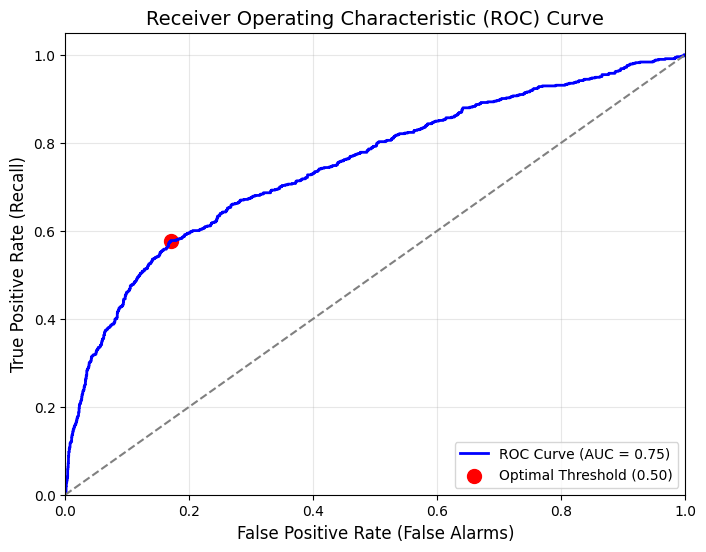

In [77]:
import numpy as np
import torch
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt

# 1. Collect all raw probabilities (before thresholding) and true targets from the test set
model.eval()
all_probs = []
all_targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        outputs = model(batch_x)
        probabilities = torch.sigmoid(outputs)
        
        all_probs.extend(probabilities.cpu().numpy())
        all_targets.extend(batch_y.cpu().numpy())

all_probs = np.array(all_probs).flatten()
all_targets = np.array(all_targets)

# 2. Calculate ROC Curve and ROC-AUC Score
fpr, tpr, thresholds = roc_curve(all_targets, all_probs)
roc_auc = auc(fpr, tpr)

print(f"\n--- Model Quality Score ---")
print(f"ROC-AUC Score: {roc_auc:.4f} (Closer to 1.0 is better!)")

# 3. Find the Optimal Threshold using Youden's J Statistic (J = tpr - fpr)
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
optimal_threshold = thresholds[best_idx]

print(f"Mathematically Optimal Threshold: {optimal_threshold:.4f}")

# 4. Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--') # Random guess line
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', s=100, label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (False Alarms)', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [79]:
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve

# 1. Get predicted probabilities from your test set
all_probs = []
all_targets = []

model.eval()
with torch.no_grad():
    for batch_x, batch_y in test_loader:
        outputs = model(batch_x)
        probs = torch.sigmoid(outputs)
        all_probs.extend(probs.cpu().numpy())
        all_targets.extend(batch_y.cpu().numpy())

all_probs = np.array(all_probs)
all_targets = np.array(all_targets)

# 2. Find the exact threshold where Recall >= 80% using ROC curve (TPR = Recall)
fpr, tpr, thresholds = roc_curve(all_targets, all_probs)
target_idx = np.where(tpr >= 0.80)[0][0]
required_threshold = thresholds[target_idx]

print(f"Adjusted Threshold for 80% Recall: {required_threshold:.4f}")

# 3. Apply the threshold and check the new Confusion Matrix
y_pred_adjusted = (all_probs >= required_threshold).astype(float)
cm = confusion_matrix(all_targets, y_pred_adjusted)

print("\nNew Confusion Matrix (At >= 80% Recall):")
print(cm)

Adjusted Threshold for 80% Recall: 0.2880

New Confusion Matrix (At >= 80% Recall):
[[1158 1179]
 [ 132  531]]


In [80]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import numpy as np

# 1. Initialize LightGBM with built-in handling for class imbalance
# scale_pos_weight handles the class ratio automatically without needing SMOTE!
ratio = (Y_train == 0).sum() / (Y_train == 1).sum()

lgb_train = lgb.Dataset(X_train_scaled, label=Y_train)
lgb_val = lgb.Dataset(X_val_scaled, label=Y_val, reference=lgb_train)

params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'scale_pos_weight': ratio, # Industry standard way to handle imbalance
    'learning_rate': 0.03,
    'num_leaves': 31,
    'max_depth': 6,
    'feature_fraction': 0.8,
    'seed': 42,
    'verbose': -1
}

# 2. Train with early stopping
callbacks = [lgb.early_stopping(stopping_rounds=30)]
model_lgb = lgb.train(
    params,
    lgb_train,
    num_boost_round=300,
    valid_sets=[lgb_val],
    callbacks=callbacks
)

# 3. Evaluate on Unseen Test Set
test_probs = model_lgb.predict(X_test_scaled)
print(f"\nLightGBM ROC-AUC Score: {roc_auc_score(Y_test, test_probs):.4f}")

# 4. Find the exact threshold for >= 80% Recall
fpr, tpr, thresholds = roc_curve(Y_test, test_probs)
target_idx = np.where(tpr >= 0.80)[0][0]
lgb_threshold = thresholds[target_idx]

y_pred_lgb = (test_probs >= lgb_threshold).astype(int)
print(f"LightGBM Threshold for 80% Recall: {lgb_threshold:.4f}")
print("\nLightGBM Confusion Matrix (At 80% Recall):")
print(confusion_matrix(Y_test, y_pred_lgb))

Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[26]	valid_0's auc: 0.786544

LightGBM ROC-AUC Score: 0.7690
LightGBM Threshold for 80% Recall: 0.3017

LightGBM Confusion Matrix (At 80% Recall):
[[1315 1022]
 [ 132  531]]


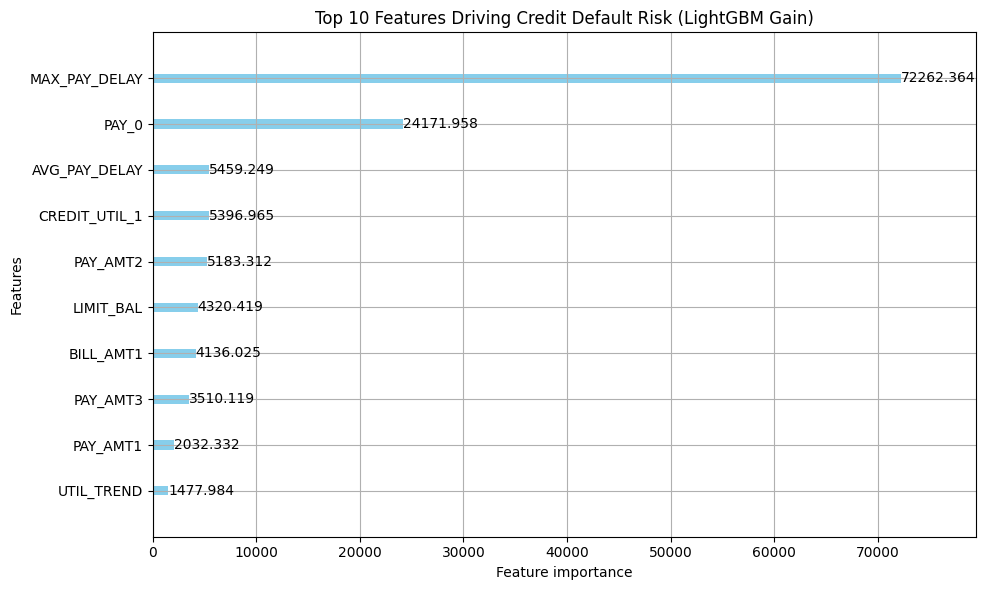

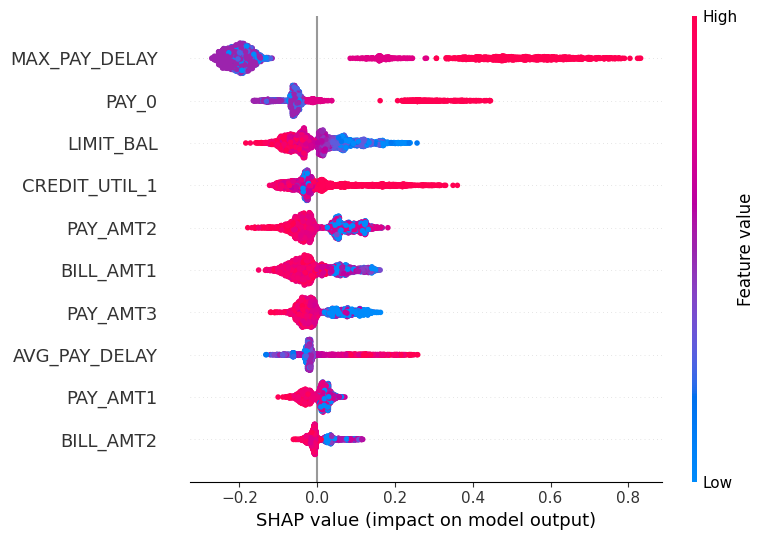

In [81]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import shap

# 1. Native LightGBM Feature Importance (Gain)
# 'gain' shows how much accuracy each feature contributes to the trees
fig, ax = plt.subplots(figsize=(10, 6))
lgb.plot_importance(
    model_lgb,
    importance_type='gain',
    ax=ax,
    max_num_features=10,
    color='skyblue',
)
plt.title('Top 10 Features Driving Credit Default Risk (LightGBM Gain)')
plt.tight_layout()
plt.show()

# 2. SHAP Values (Industry Standard for Explainable AI & Adverse Action)
# TreeExplainer calculates the exact marginal contribution of each feature
explainer = shap.TreeExplainer(model_lgb)
shap_values = explainer(X_test_scaled)

# Global Summary Plot (Shows which features push towards default vs no default)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_scaled, max_display=10)

In [82]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split

# 1. Ensure your dataframe 'data' has the trend features from earlier:
# data['PAY_DELAY_TREND'] = data['PAY_0'] - data['PAY_6']
# data['MAX_PAY_DELAY'] = data[pay_cols].max(axis=1)
# data['AVG_PAY_DELAY'] = data[pay_cols].mean(axis=1)
# data['UTIL_TREND'] = data['CREDIT_UTIL_1'] - data['CREDIT_UTIL_6']
# data['PAY_RATIO_TREND'] = data['PAY_BILL_RATIO_1'] - data['PAY_BILL_RATIO_6']

# 2. Define Features and Target
X = data.drop(columns=['default.payment.next.month', 'ID'], errors='ignore')
y = data['default.payment.next.month']

# 3. Stratified Train/Test Split (Matching your pipeline setup)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Initialize and Train LightGBM with Class Balancing (scale_pos_weight)
# scale_pos_weight helps handle the ~22% imbalance natively
pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

model_lgb = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=31,
    scale_pos_weight=pos_weight,
    random_state=42,
    n_jobs=-1,
)

model_lgb.fit(X_train, y_train)

# 5. Predict Probabilities on Test Set
y_probs = model_lgb.predict_proba(X_test)[:, 1]

# 6. Programmatically Find Threshold for >= 80% Recall
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
target_idx = np.where(tpr >= 0.80)[0][0]
best_threshold = thresholds[target_idx]

print(f'Optimal Threshold for >= 80% Recall: {best_threshold:.4f}')

# 7. Apply Threshold and Evaluate Confusion Matrix
y_pred_lgb = (y_probs >= best_threshold).astype(int)
cm_lgb = confusion_matrix(y_test, y_pred_lgb)

print('\nLightGBM + Trend Features Confusion Matrix:')
print(cm_lgb)
print('\nClassification Report:')
print(classification_report(y_test, y_pred_lgb))

Optimal Threshold for >= 80% Recall: 0.3542

LightGBM + Trend Features Confusion Matrix:
[[2628 2045]
 [ 265 1062]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.56      0.69      4673
           1       0.34      0.80      0.48      1327

    accuracy                           0.61      6000
   macro avg       0.63      0.68      0.59      6000
weighted avg       0.78      0.61      0.65      6000

